# VWAP Drift 01 — conditional drift toward VWAP in volatility-engine units

Pre-registration: `discussions/VWAP_Drift/001_claude_vwd01_preregistration.md`. Code: `src/data_engineering/modeling/vwap_drift.py`.

The question behind a directional option toward VWAP: is
$$\mathbb E\big[\,-\operatorname{sign}(D_t)\,(\log C_{t+h}-\log C_t)\;\big|\;|Z_t|,\ \text{vol regime},\ \text{jump}\big] > \text{costs},\qquad Z_t=D_t/\sigma^{\text{engine}}_{t,h}$$
at $h\in\{15, 60, 240\}$ min and to the next 08:00 expiry? Perpetual only; options only if the gates pass.

Environment: `VWD01_ASSETS` (default `BTC,ETH,SOL,XRP`), `VWD01_SYNTHETIC=1` (synthetic smoke run, outputs to a temp dir), `BINANCE_UM_DIR`.

In [1]:
import os, sys, json, time, subprocess, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import vwap_drift as vd

SYNTHETIC = os.getenv('VWD01_SYNTHETIC', '0') == '1'
ASSETS = [a.strip().upper() for a in os.getenv('VWD01_ASSETS', ','.join(vd.ASSETS)).split(',') if a.strip()]
P = vd.Params()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='vwd01-')) / '01'; P = vd.Params(n_boot=300, n_boot_table=100)
else:
    OUT = ROOT / 'notebooks' / 'VWAP_Drift' / '01'
    BIN = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_vwap_drift.py'],
                     cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr[-200:]); assert chk.returncode == 0, 'tests failed'
FITS = vd.load_engine(ROOT / 'notebooks' / 'Volatility_Dynamics' / '18' / '18_manifest.json')
print(json.dumps(vd.registration(P), indent=1, default=str))

..............
----------------------------------------------------------------------
Ran 14 tests in 16.233s

OK

{
 "grid_min": 5,
 "warmup_min": 30,
 "entry_lag": 1,
 "min_exp_min": 15,
 "jump_k": 4.0,
 "jump_lookback": 60,
 "vol_h": 60,
 "tradeable_bp": 7.0,
 "option_fee_floor_bp": 12.0,
 "min_dev_days": 30,
 "min_dev_n": 500,
 "min_test_days": 20,
 "n_boot": 2000,
 "n_boot_table": 400,
 "s1_alpha": 0.05,
 "seed": 20261024,
 "status": "PREREGISTERED_VWD001",
 "version": "VWD01-0.1.0",
 "test_start": "2026-04-01 00:00:00+00:00",
 "assets": [
  "BTC",
  "ETH",
  "SOL",
  "XRP"
 ],
 "horizons": [
  "15",
  "60",
  "240",
  "EXP"
 ],
 "anchors": [
  {
   "name": "session",
   "kind": "real",
   "period_min": 1440,
   "phase_min": 480
  },
  {
   "name": "session",
   "kind": "placebo",
   "period_min": 1440,
   "phase_min": 120
  },
  {
   "name": "session",
   "kind": "placebo",
   "period_min": 1440,
   "phase_min": 840
  },
  {
   "name": "session",
   "kind": "placebo",
   "period_

## 1. Origins, engine forecasts and outcomes (all anchors, real and placebo)

In [2]:
T0 = time.time(); parts, cov = [], []
for k, a in enumerate(ASSETS):
    if SYNTHETIC:
        df = vd.synthetic_klines(300, seed=11 + k, start='2025-09-01', kappa=0.0)
    else:
        df = pd.read_parquet(BIN / f'{a}USDT_um_1m.parquet', columns=['open_time', 'high', 'low', 'close', 'volume', 'quote_volume'])
    A, info = vd.run_asset(df, a, FITS, P); del df
    parts.append(A); cov.append(info); print(a, f'{time.time() - T0:.0f}s', info['origins'], 'origins')
A = pd.concat(parts, ignore_index=True); del parts
cov = pd.DataFrame(cov); display(cov)
display(A.groupby(['kind', 'test', 'h'], observed=True)['n'].sum().unstack('h'))

BTC 6s 213408 origins
ETH 12s 213408 origins
SOL 16s 213408 origins
XRP 21s 213408 origins


,asset,first_bar,last_bar,bars,missing_bars,origins,engine_nan_share,vol_cutoffs_log_v60,dev_origins
0,BTC,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,0,213408,0.00135,"[-11.49485420894064, -10.744880300531735]",157535
1,ETH,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,0,213408,0.00135,"[-10.582228719952193, -9.90790612905345]",157535
2,SOL,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,0,213408,0.00135,"[-10.205792710348325, -9.609499177912634]",157535
3,XRP,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,0,213408,0.00135,"[-10.434923732463083, -9.641359612623411]",157535


h                   15      240       60      EXP
kind    test                                     
placebo False  3498712  3498712  3498712  3472504
        True   1243080  1242096  1242888  1229568
real    False  1166216  1166216  1166216  1157480
        True    414360   414024   414288   409864

## 2. Pre-registered decision: DEV selection, TEST gates

In [3]:
dev = vd.dev_table(A, P).sort_values('dev_lo', ascending=False)
display(dev.head(12).round(3))
cell = vd.select(dev, P)
decision = vd.evaluate(A, cell, P)
print(json.dumps(decision, indent=1, default=float))
print('VERDICT:', decision['verdict'])

,anchor,h,zb,vol,jump,dev_mean,dev_lo,dev_hi,dev_n,dev_days,dev_hit,dev_p0
24,h4,240,z2_3,high,0,113.383,110.121,167.217,35,2,0.000,0.028
90,session,240,z2_3,high,0,33.101,7.317,61.789,7993,261,0.041,0.023
126,session,EXP,z2_3,high,0,51.677,5.260,101.860,4405,229,0.082,0.021
43,h4,60,z3p,high,1,81.183,4.219,220.506,17,9,0.118,0.002
17,h4,15,z3p,high,1,10.283,3.306,18.886,2596,320,0.014,0.002
59,h4,EXP,z3p,mid,1,20.505,2.700,40.430,20,13,0.000,0.001
114,session,60,z3p,high,0,7.199,1.529,13.321,19277,364,0.005,0.001
30,h4,60,z1_2,high,0,4.799,0.917,8.968,24386,470,0.190,0.206
28,h4,60,z1_2,mid,0,2.763,0.406,5.132,19241,518,0.186,0.218
45,h4,EXP,z1_2,low,1,7.566,0.400,14.983,370,104,0.208,0.197


{
 "version": "VWD01-0.1.0",
 "status": "PREREGISTERED_VWD001",
 "cell": {
  "anchor": "session",
  "h": "240",
  "zb": "z2_3",
  "vol": "high",
  "jump": 0,
  "dev_mean": 33.10052988789108,
  "dev_lo": 7.316586535801156,
  "dev_n": 7993,
  "dev_days": 261
 },
 "test_n": 704,
 "test_days": 42,
 "test_mean_bp": 33.992530645904246,
 "test_lo": -46.142088105049496,
 "test_hi": 103.88510300315747,
 "placebo_mean_bp": 5.326609437888895,
 "real_minus_placebo_hour_matched": -13.957722230715337,
 "diff_lo": -89.33350748572654,
 "diff_hi": 49.94896538385092,
 "test_hit_rate": 0.11505681818181818,
 "test_p0_mean": 0.022381129232275004,
 "G1_vwap_specific": "FAIL",
 "G2_tradeable": "FAIL",
 "options_fee_floor_bp": 12.0,
 "options_considered": false,
 "verdict": "NO_EDGE"
}
VERDICT: NO_EDGE


## 3. Secondary S1 — high-volatility regime, |Z| ≥ 2 (Ivan's hypothesis), Bonferroni over 8

In [4]:
s1 = vd.secondary_s1(A, P)
display(s1.round(3))

,anchor,h,n,days,mean_bp,lo,hi,diff,diff_lo,diff_hi,placebo_mean,ci_level,pass_vwap_specific,pass_tradeable
0,session,15,15824,152,0.995,-1.451,3.121,0.552,-0.428,1.499,0.491,0.994,False,False
1,session,60,6522,123,3.730,-9.445,16.687,-4.006,-11.899,3.128,5.147,0.994,False,False
2,session,240,1294,51,26.415,-61.690,116.208,-7.927,-83.457,44.195,7.610,0.994,False,False
3,session,EXP,927,40,45.821,-19.597,121.167,-0.489,-28.995,32.388,41.004,0.994,False,False
4,h4,15,5577,140,1.290,-2.702,5.035,0.571,-2.503,3.867,0.801,0.994,False,False
5,h4,60,461,58,11.393,-31.129,50.979,-30.652,-120.335,19.249,46.867,0.994,False,False
6,h4,240,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.994,False,False
7,h4,EXP,46,11,16.478,-39.456,119.177,2.512,-174.950,102.755,13.966,0.994,False,False


## 4. Descriptive tables (no decision)

In [5]:
tz = vd.table(A, ['anchor', 'h', 'zb'], P, seed=11)
tv = vd.table(A[A.zb.isin(['z2_3', 'z3p'])], ['anchor', 'h', 'vol'], P, seed=12)
tj = vd.table(A[A.zb.isin(['z2_3', 'z3p'])], ['anchor', 'h', 'jump'], P, seed=13)
cells = vd.table(A, vd.CELL, P, seed=14)
show = ['mean_bp', 'lo', 'hi', 'placebo_mean_bp', 'diff', 'diff_lo', 'diff_hi', 'hit', 'p0', 'n', 'days']
print('TEST, by |Z| bucket'); display(tz[tz.test].set_index(['anchor', 'h', 'zb'])[show].round(2))
print('TEST, |Z| >= 2, by volatility tercile'); display(tv[tv.test].set_index(['anchor', 'h', 'vol'])[show].round(2))
print('TEST, |Z| >= 2, by recent jump'); display(tj[tj.test].set_index(['anchor', 'h', 'jump'])[show].round(2))

TEST, by |Z| bucket


mean_bp     lo     hi  placebo_mean_bp   diff  diff_lo  diff_hi   hit    p0       n  days
anchor  h   zb                                                                                             
h4      15  z0_1     0.10  -0.16   0.37             0.19  -0.09    -0.37     0.15  0.58  0.64  110809   194
            z1_2     0.26  -0.24   0.75             0.23   0.03    -0.34     0.44  0.15  0.19   60056   194
            z2_3     0.38  -0.50   1.45             0.04   0.34    -0.62     1.34  0.03  0.03   19314   194
            z3p      1.60  -0.86   3.67             1.98  -0.34    -2.21     1.34  0.01  0.00    5361   188
        240 z0_1     2.85   0.50   5.16             0.86   2.00     0.28     3.81  0.80  0.82  194311   194
            z1_2    27.65   2.43  56.29            51.05 -18.60   -48.93    10.46  0.26  0.25    1073    99
        60  z0_1     0.95   0.09   1.89             0.44   0.49    -0.24     1.10  0.66  0.70  172726   194
            z1_2     1.43  -1.87   4.39             0.56   0.86    -2.20     3.87  0.18  0.22   21888   194
            z2_3     4.15 -14.11  20.93            26.38 -20.01   -46.81     5.48  0.06  0.03     868    98
            z3p      7.07 -60.04  88.02            68.68 -45.64  -163.30    39.63  0.00  0.00      22     6
        EXP z0_1     2.89  -1.18   6.54            -0.20   3.19    -0.63     6.94  0.85  0.87  189922   194
            z1_2     9.10   1.78  18.23            16.78   0.05    -5.92     5.68  0.18  0.21    2912   192
            z2_3    -0.38  -7.66   8.59             1.16  -1.54   -11.04     7.39  0.02  0.03     415    96
            z3p     -9.72 -26.78   1.21            -4.58  -5.14   -16.43     4.39  0.00  0.00      79    33
session 15  z0_1     0.28  -0.01   0.57             0.05   0.31    -0.03     0.67  0.57  0.63   61538   194
            z1_2    -0.17  -0.59   0.25             0.07  -0.21    -0.63     0.20  0.14  0.17   49239   194
            z2_3     0.15  -0.36   0.77            -0.01   0.19    -0.33     0.78  0.03  0.02   34972   194
            z3p      0.16  -0.43   0.73             0.20  -0.13    -0.44     0.15  0.00  0.00   73071   194
        240 z0_1    -1.26  -4.87   1.71            -1.37   0.26    -2.73     3.14  0.66  0.71  174430   194
            z1_2    -3.34 -11.49   8.00            -1.31  -1.97    -6.93     2.99  0.13  0.19   37663   193
            z2_3    -8.44 -29.01  13.88             2.05 -15.06   -27.33    -2.02  0.02  0.02    5941   105
            z3p    -12.75 -55.08  51.31             8.68 -18.66   -52.89    17.05  0.03  0.00     606    19
        60  z0_1     0.06  -0.92   1.04             0.16   0.00    -0.97     1.13  0.60  0.66  113891   194
            z1_2     0.57  -1.12   2.31            -0.07   0.71    -0.54     1.87  0.14  0.17   58179   194
            z2_3    -0.52  -2.95   2.25             0.55  -1.55    -3.44     0.26  0.02  0.02   27493   193
            z3p     -0.27  -4.24   3.77             0.33  -1.79    -4.24     0.61  0.01  0.00   19221   178
        EXP z0_1    -2.31  -9.65   4.97            -1.76  -0.73    -7.60     5.00  0.74  0.78  183156   194
            z1_2     0.01 -12.40  10.57             2.26  -0.53    -6.42     6.58  0.12  0.18   21983   194
            z2_3     7.35  -4.05  18.47             4.93   2.57    -3.72     9.04  0.02  0.02    6327   188
            z3p      0.03 -11.59   9.78             1.00  -2.76    -8.44     1.59  0.00  0.00    5070   175

TEST, |Z| >= 2, by volatility tercile


mean_bp     lo     hi  placebo_mean_bp   diff  diff_lo  diff_hi   hit    p0      n  days
anchor  h   vol                                                                                           
h4      15  low      0.60  -0.16   1.45             0.16   0.31    -0.32     0.94  0.03  0.02  11891   187
            mid      0.22  -1.26   1.68             0.68  -0.36    -1.84     0.95  0.02  0.02   7207   180
            high     1.29  -1.97   3.79             0.80   0.57    -1.40     2.81  0.02  0.02   5577   140
        60  low     -0.30 -12.37  10.25            13.64 -12.88   -25.15    -1.58  0.06  0.03    160    46
            mid     -5.38 -22.51  11.29            -1.42  -4.28   -22.92    16.06  0.03  0.03    269    53
            high    11.39 -19.35  39.59            46.87 -30.65   -81.37     7.20  0.08  0.03    461    58
        EXP low     -6.12 -16.13   3.02            -1.02  -5.10   -10.82    -0.25  0.03  0.02    317    72
            mid      1.97  -3.70   9.10            -1.02   3.00    -2.04     6.65  0.01  0.02    131    44
            high    16.48 -28.97  88.81            13.97   2.51  -126.22    73.63  0.02  0.02     46    11
session 15  low     -0.28  -0.70   0.18            -0.02  -0.25    -0.51     0.01  0.01  0.01  63487   189
            mid      0.65  -0.10   1.43             0.25   0.18    -0.17     0.57  0.01  0.01  28732   184
            high     1.00  -0.78   2.61             0.49   0.55    -0.19     1.20  0.01  0.01  15824   152
        240 low    -19.84 -34.76  -4.59             1.31 -15.06   -33.18     1.03  0.00  0.02   3509    78
            mid    -12.87 -47.12  18.49            -1.78 -19.95   -47.75     3.93  0.02  0.02   1744    75
            high    26.41 -26.21  94.30             7.61  -7.93   -58.38    32.86  0.09  0.02   1294    51
        60  low     -1.77  -4.18   0.46            -0.70  -0.88    -2.44     0.52  0.01  0.01  27921   183
            mid      0.45  -4.42   4.86            -0.22  -1.28    -3.39     0.73  0.01  0.01  12271   173
            high     3.73  -4.73  12.74             5.15  -4.01    -9.97     1.23  0.02  0.01   6522   123
        EXP low     -2.03 -11.25   5.74            -1.68   0.84    -3.33     5.60  0.01  0.01   7929   175
            mid      7.99  -6.87  24.18             5.81   1.05    -8.00    10.46  0.01  0.01   2541   104
            high    45.82  -4.16  99.74            41.00  -0.49   -21.02    20.92  0.07  0.01    927    40

TEST, |Z| >= 2, by recent jump


mean_bp     lo     hi  placebo_mean_bp   diff  diff_lo  diff_hi   hit    p0      n  days
anchor  h   jump                                                                                          
h4      15  0        0.90  -0.14   2.12             0.87   0.08    -0.80     1.02  0.03  0.02  18154   194
            1       -0.06  -2.07   2.08            -0.67   0.60    -0.62     1.96  0.03  0.02   6521   194
        60  0        6.54 -12.09  23.94            35.06 -26.02   -52.35     2.39  0.05  0.03    627    88
            1       -1.31 -26.15  25.53            11.27  -9.84   -34.34    26.17  0.06  0.03    263    53
        EXP 0       -3.14 -12.03   5.08             0.95  -4.09   -13.09     3.24  0.02  0.02    393    87
            1        3.07  -6.42  15.56             0.07   3.00    -7.93    17.14  0.03  0.03    101    34
session 15  0        0.14  -0.31   0.58             0.15  -0.04    -0.30     0.21  0.01  0.01  86012   194
            1        0.24  -0.60   1.09             0.06   0.10    -0.35     0.57  0.01  0.01  22031   194
        240 0      -11.62 -29.54   9.51             1.99 -18.64   -37.21    -2.27  0.02  0.02   5116   101
            1        1.09 -20.53  30.06             4.13  -3.25   -21.83    11.26  0.02  0.02   1431    81
        60  0       -0.68  -3.47   2.02             0.32  -1.74    -3.38     0.26  0.02  0.01  36959   192
            1        0.57  -3.93   4.59             1.03  -1.19    -3.50     0.86  0.01  0.01   9755   190
        EXP 0        3.51  -5.54  13.17             3.66  -0.58    -6.06     4.60  0.01  0.01   9250   185
            1        6.61  -4.51  16.90             2.45   3.56    -4.33    12.14  0.01  0.01   2147   130

## 5. Figures

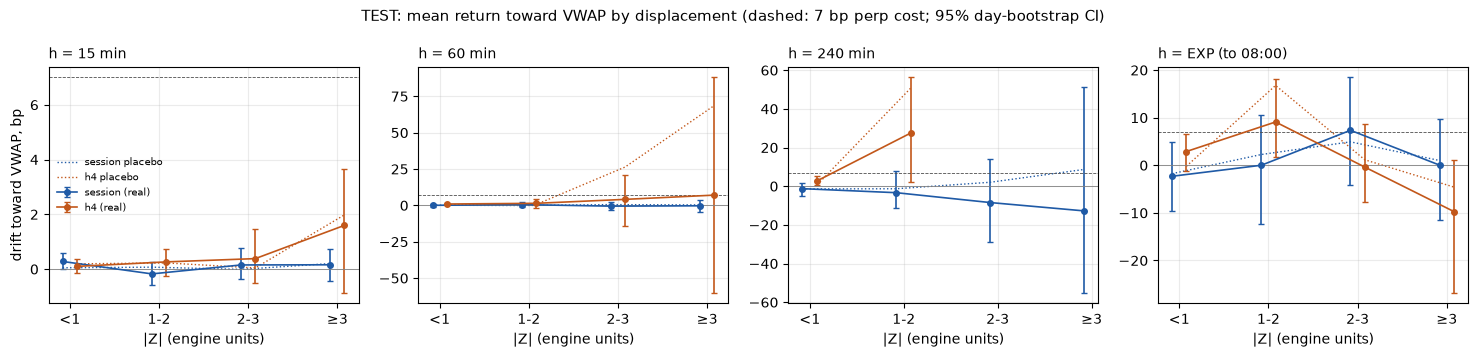

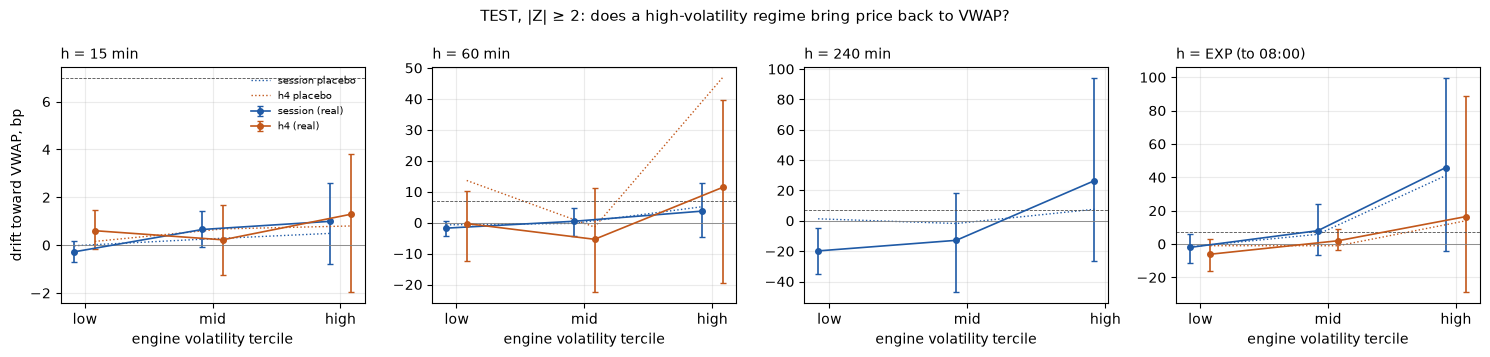

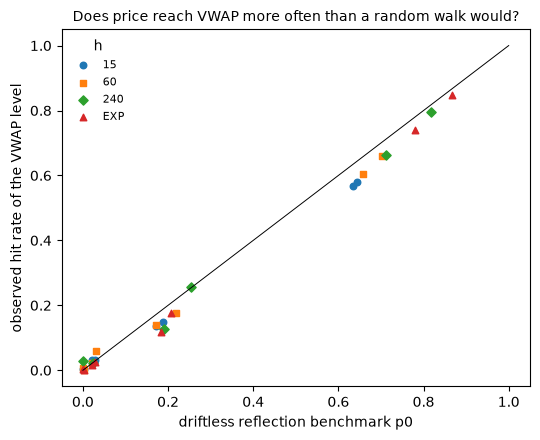

In [6]:
H = list(vd.HORIZONS); ZL = list(vd.ZB)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
for ax, h in zip(axes, H):
    for an, col in (('session', '#1f5aa6'), ('h4', '#c2571a')):
        d = tz[(tz.test) & (tz.anchor == an) & (tz.h == h)].set_index('zb').reindex(ZL)
        x = np.arange(len(ZL)) + (-0.08 if an == 'session' else 0.08)
        ax.errorbar(x, d.mean_bp, yerr=[d.mean_bp - d.lo, d.hi - d.mean_bp], fmt='o-', color=col, ms=4, lw=1.2, capsize=2, label=f'{an} (real)')
        ax.plot(x, d.placebo_mean_bp, ls=':', color=col, lw=1, label=f'{an} placebo')
    ax.axhline(0, color='0.5', lw=0.6); ax.axhline(P.tradeable_bp, color='0.3', lw=0.6, ls='--')
    ax.set_xticks(range(len(ZL))); ax.set_xticklabels(['<1', '1-2', '2-3', '≥3']); ax.set_xlabel('|Z| (engine units)')
    ax.set_title(f'h = {h}' + (' min' if h != 'EXP' else ' (to 08:00)'), loc='left', fontsize=10); ax.grid(alpha=0.25)
axes[0].set_ylabel('drift toward VWAP, bp'); axes[0].legend(fontsize=7, frameon=False)
fig.suptitle('TEST: mean return toward VWAP by displacement (dashed: 7 bp perp cost; 95% day-bootstrap CI)', fontsize=11)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, h in zip(axes, H):
    for an, col in (('session', '#1f5aa6'), ('h4', '#c2571a')):
        d = tv[(tv.test) & (tv.anchor == an) & (tv.h == h)].set_index('vol').reindex(list(vd.VOL))
        x = np.arange(3) + (-0.08 if an == 'session' else 0.08)
        ax.errorbar(x, d.mean_bp, yerr=[d.mean_bp - d.lo, d.hi - d.mean_bp], fmt='o-', color=col, ms=4, lw=1.2, capsize=2, label=f'{an} (real)')
        ax.plot(x, d.placebo_mean_bp, ls=':', color=col, lw=1, label=f'{an} placebo')
    ax.axhline(0, color='0.5', lw=0.6); ax.axhline(P.tradeable_bp, color='0.3', lw=0.6, ls='--')
    ax.set_xticks(range(3)); ax.set_xticklabels(vd.VOL); ax.set_xlabel('engine volatility tercile')
    ax.set_title(f'h = {h}' + (' min' if h != 'EXP' else ' (to 08:00)'), loc='left', fontsize=10); ax.grid(alpha=0.25)
axes[0].set_ylabel('drift toward VWAP, bp'); axes[0].legend(fontsize=7, frameon=False)
fig.suptitle('TEST, |Z| ≥ 2: does a high-volatility regime bring price back to VWAP?', fontsize=11)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
d = tz[tz.test]
for h, mk in zip(H, 'osD^'):
    g = d[d.h == h]; ax.scatter(g.p0, g.hit, marker=mk, s=22, label=h)
ax.plot([0, 1], [0, 1], color='k', lw=0.7)
ax.set_xlabel('driftless reflection benchmark p0'); ax.set_ylabel('observed hit rate of the VWAP level')
ax.legend(title='h', fontsize=8, frameon=False); ax.set_title('Does price reach VWAP more often than a random walk would?', fontsize=10)
plt.tight_layout(); plt.show()

## 6. Exports

In [7]:
dev.to_csv(OUT / '01_dev_selection.csv', index=False, float_format='%.6g')
s1.to_csv(OUT / '01_secondary_s1.csv', index=False, float_format='%.6g')
tz.to_csv(OUT / '01_by_zbucket.csv', index=False, float_format='%.6g')
tv.to_csv(OUT / '01_by_vol_regime.csv', index=False, float_format='%.6g')
tj.to_csv(OUT / '01_by_jump.csv', index=False, float_format='%.6g')
cells.to_csv(OUT / '01_all_cells.csv', index=False, float_format='%.6g')
cov.to_csv(OUT / '01_coverage.csv', index=False)
(OUT / '01_decision.json').write_text(json.dumps({'decision': decision, 'registration': vd.registration(P)}, indent=1, default=float))
(OUT / '01_manifest.json').write_text(json.dumps({'module': 'VWAP_Drift_01', 'version': vd.VERSION, 'synthetic': SYNTHETIC,
    'assets': ASSETS, 'origins_total': int(A.n.sum()), 'runtime_s': round(time.time() - T0, 1)}, indent=1))
print(sorted(p.name for p in OUT.iterdir()))

['01_all_cells.csv', '01_by_jump.csv', '01_by_vol_regime.csv', '01_by_zbucket.csv', '01_coverage.csv', '01_decision.json', '01_dev_selection.csv', '01_manifest.json', '01_secondary_s1.csv']
